# 从 npy 文件绘制 DE area spectrum

本 notebook 读取同目录下的 `DE_spectrum_*.npy`，并参照 `20260824_read_results.ipynb` 末尾
`plot_area_spectrum` 的画法（`ax.stairs(freq, edges=bins)` + log y），绘制 pattern cut 前后的
Pile-up DE area spectrum。

- `DE_spectrum_bins.npy`：area 分箱边界
- `DE_spectrum_before_cut_counts.npy` / `DE_spectrum_after_cut_counts.npy`：cut 前后计数
- `DE_spectrum_before_cut_freq.npy` / `DE_spectrum_after_cut_freq.npy`：cut 前后归一化频率

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 自动定位 DE_spectrum_*.npy 所在目录：优先当前目录，其次向上逐级查找。
def _find_data_dir():
    anchor = Path.cwd()
    for base in [anchor, *anchor.parents]:
        if (base / "DE_spectrum_bins.npy").exists():
            return base
    raise FileNotFoundError("未找到 DE_spectrum_bins.npy，请在 notebooks/ 目录运行本 notebook。")

DATA_DIR = _find_data_dir()
print("数据目录:", DATA_DIR)

bins = np.load(DATA_DIR / "DE_spectrum_bins.npy")
counts_before = np.load(DATA_DIR / "DE_spectrum_before_cut_counts.npy")
counts_after = np.load(DATA_DIR / "DE_spectrum_after_cut_counts.npy")
freq_before = np.load(DATA_DIR / "DE_spectrum_before_cut_freq.npy")
freq_after = np.load(DATA_DIR / "DE_spectrum_after_cut_freq.npy")

print("bins:", bins.shape, "| counts:", counts_before.shape, counts_after.shape)
print("总计数 before =", counts_before.sum(), ", after =", counts_after.sum())

数据目录: /home/leiyang/TPC_DE_SIm-test/notebooks
bins: (28,) | counts: (27,) (27,)
总计数 before = 342993746 , after = 150


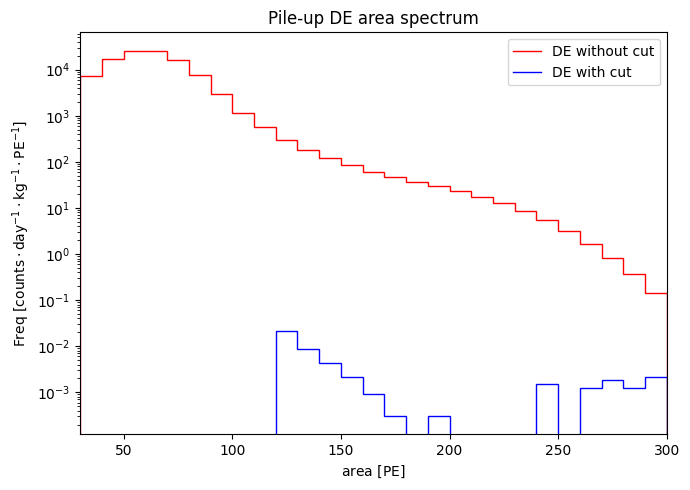

In [2]:
# 参照 20260824_read_results.ipynb 末尾 plot_area_spectrum 的画法：
# ax.stairs(freq, edges=bins)，log y；红色为 cut 前，蓝色为 cut 后。
def plot_spectrum(edges, freq_before, freq_after, title="Pile-up DE area spectrum"):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.stairs(freq_before, edges=edges, label="DE without cut", color="red")
    ax.stairs(freq_after, edges=edges, label="DE with cut", color="blue")
    ax.set_xlabel(r"$\mathrm{area\ [PE]}$")
    ax.set_ylabel(r"$\mathrm{Freq\ [counts \cdot day^{-1} \cdot kg^{-1} \cdot PE^{-1}]}$")
    ax.set_yscale("log")
    ax.set_title(title)
    ax.legend()
    ax.set_xlim(edges[0], edges[-1])
    fig.tight_layout()
    return fig, ax

fig, ax = plot_spectrum(bins, freq_before, freq_after)
plt.show()

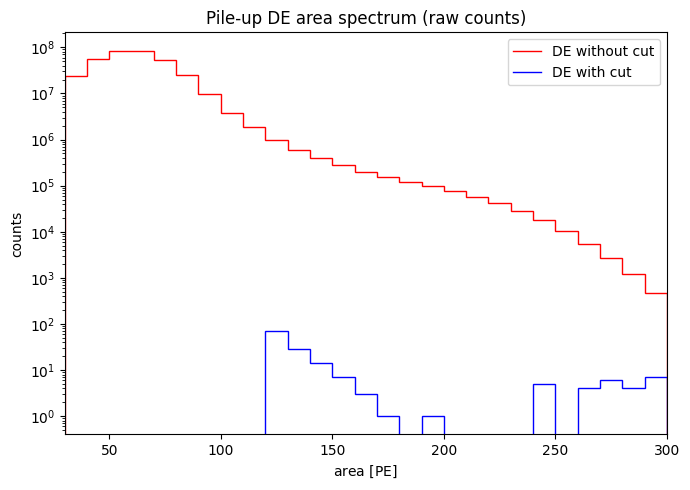

In [3]:
# 计数版（未归一化），便于直接核对每个分箱的事件数。
fig, ax = plt.subplots(figsize=(7, 5))
ax.stairs(counts_before, edges=bins, label="DE without cut", color="red")
ax.stairs(counts_after, edges=bins, label="DE with cut", color="blue")
ax.set_xlabel(r"$\mathrm{area\ [PE]}$")
ax.set_ylabel("counts")
ax.set_yscale("log")
ax.set_title("Pile-up DE area spectrum (raw counts)")
ax.legend()
ax.set_xlim(bins[0], bins[-1])
fig.tight_layout()
plt.show()